<a href="https://colab.research.google.com/github/Paulmora23/ENTREGABLE_BIT_PAULAMOLINA/blob/main/Taller_Aprendizaje_no_supervisado.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**1-Exploración de los datos**

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
df = pd.read_csv('/content/steam-200k.csv', header=None)

Limpieza incial de columnas

In [ ]:
if df.shape[1] == 5:
    df = df.drop(columns=[4])

df.columns = ['user_id', 'game_title', 'behavior', 'value']

In [ ]:
# 1. Dimensiones y tipos
print(f"Dimensiones: {df.shape[0]} filas, {df.shape[1]} columnas")
print("\nTipos de variables:")
print(df.dtypes)

Dimensiones: 200000 filas, 4 columnas

Tipos de variables:
user_id         int64
game_title     object
behavior       object
value         float64
dtype: object


In [ ]:
# 2. Valores nulos y duplicados
print("\nValores nulos por columna:")
print(df.isnull().sum())

duplicados = df.duplicated().sum()
print(f"\nRegistros duplicados exactos: {duplicados}")
if duplicados > 0:
    df = df.drop_duplicates()


Valores nulos por columna:
user_id       0
game_title    0
behavior      0
value         0
dtype: int64

Registros duplicados exactos: 707


In [ ]:
# 3. Estadísticos descriptivos
print("\nEstadísticos de horas de juego ('play'):")
print(df[df['behavior'] == 'play']['value'].describe())


Estadísticos de horas de juego ('play'):
count    70489.000000
mean        48.878063
std        229.335236
min          0.100000
25%          1.000000
50%          4.500000
75%         19.100000
max      11754.000000
Name: value, dtype: float64


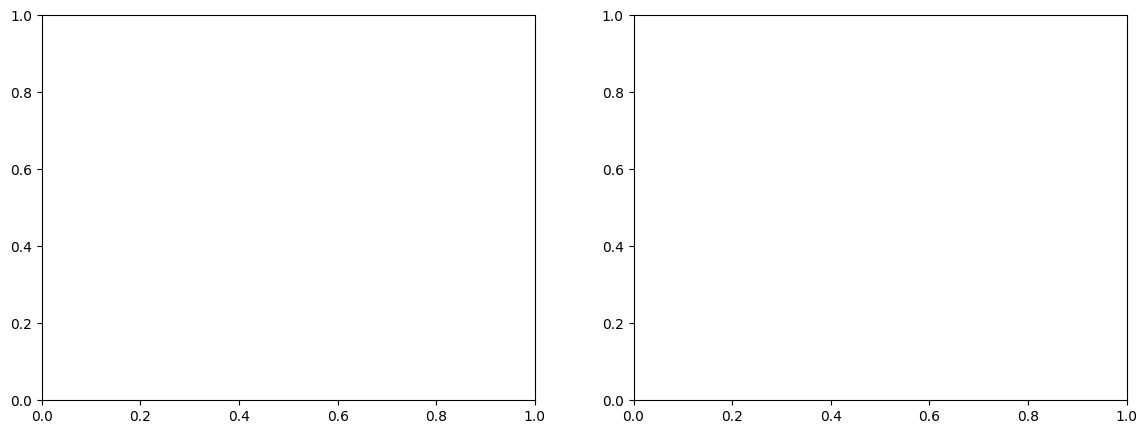

In [ ]:
# 4. Visualizaciones exploratorias
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

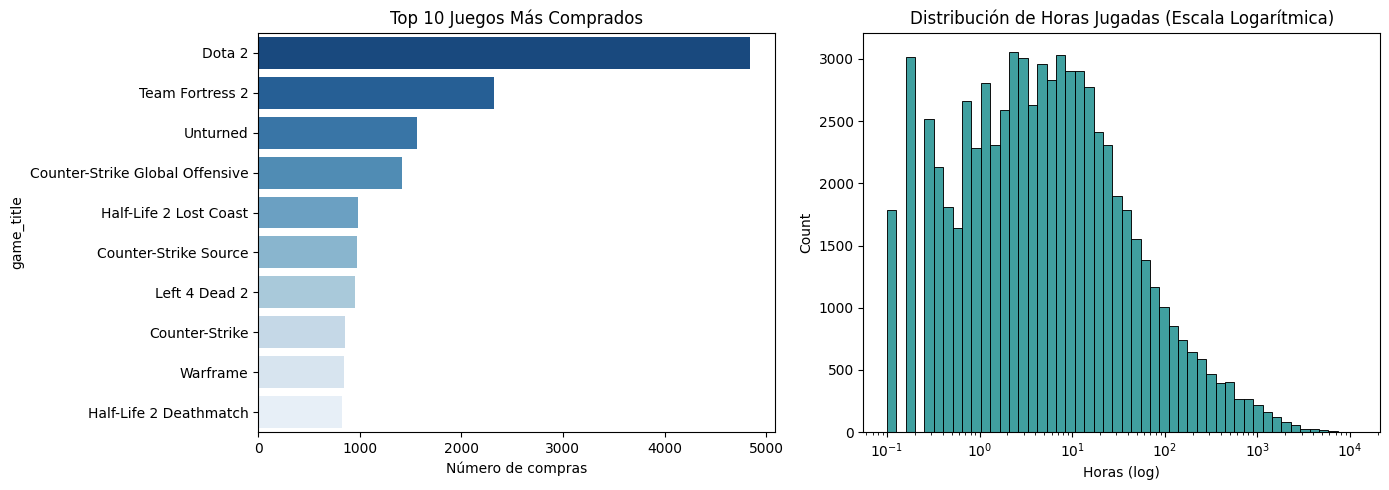

In [ ]:
# Crear la cuadrícula de 1 fila x 2 columnas
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Top 10 juegos más comprados (tu código actual)
top_games = df[df['behavior'] == 'purchase']['game_title'].value_counts().head(10)
sns.barplot(
    x=top_games.values,
    y=top_games.index,
    hue=top_games.index,
    palette='Blues_r',
    legend=False,
    ax=axes[0]
)
axes[0].set_title('Top 10 Juegos Más Comprados')
axes[0].set_xlabel('Número de compras')

# Segunda gráfica: distribución de horas
sns.histplot(df[df['behavior'] == 'play']['value'], bins=50, log_scale=True, ax=axes[1], color='teal')
axes[1].set_title('Distribución de Horas Jugadas (Escala Logarítmica)')
axes[1].set_xlabel('Horas (log)')

plt.tight_layout()
plt.show()

**2. Preparación de los Datos**

**Unidad de análisis:**

* El objetivo del negocio es segmentar usuarios, no transacciones individuales. Por tanto, se debe transformar el dataset transaccional en un dataset tabular donde cada fila represente un único user_id.    

* Extracción de variables de comportamiento:total_purchased: Total de juegos comprados (amplitud del catálogo del usuario).total_played: Cantidad de juegos a los que realmente ha entrado a jugar.   

* total_hours: Suma acumulada de horas dedicadas a jugar.   
play_ratio: Porcentaje de juegos jugados sobre el total de comprados (total_played / total_purchased).

* Permite identificar a usuarios que compran en rebajas pero acumulan juegos sin abrir (el clásico backlog de Steam).   

* avg_hours_per_game: Intensidad media de juego en los títulos que prueba.

* Tratamiento de asimetría y escalado: Las horas de juego y las compras tienen distribuciones fuertemente asimétricas a la derecha (presencia de usuarios con miles de horas en títulos competitivos como Dota 2 o CS:GO). Se aplica una transformación logarítmica $\log(x + 1)$ para estabilizar la varianza, seguida de StandardScaler para que todas las variables tengan media 0 y varianza 1

In [17]:
from sklearn.preprocessing import StandardScaler

# Separar compras y horas de juego
purchases = df[df['behavior'] == 'purchase'].groupby('user_id')['game_title'].count().rename('total_purchased')
plays = df[df['behavior'] == 'play'].groupby('user_id').agg(
    total_played=('game_title', 'count'),
    total_hours=('value', 'sum')
)

# Unir métricas por usuario
users_df = pd.concat([purchases, plays], axis=1).fillna(0)

# Variables derivadas
users_df['play_ratio'] = users_df['total_played'] / users_df['total_purchased']
users_df['avg_hours_per_game'] = np.where(
    users_df['total_played'] > 0,
    users_df['total_hours'] / users_df['total_played'],
    0
)

# Corrección de casos borde (si play_ratio > 1 por registros huérfanos)
users_df['play_ratio'] = users_df['play_ratio'].clip(upper=1.0)

# Selección de variables para el clustering
features = ['total_purchased', 'total_hours', 'play_ratio', 'avg_hours_per_game']

# Transformación logarítmica para reducir asimetría en variables de escala
users_transformed = users_df[features].copy()
for col in ['total_purchased', 'total_hours', 'avg_hours_per_game']:
    users_transformed[col] = np.log1p(users_transformed[col])

# Escalado estándar
scaler = StandardScaler()
X_scaled = scaler.fit_transform(users_transformed)

3. **Modelado**

Selección de K-Means: Es ideal para segmentaciones de clientes debido a su interpretabilidad mediante centroides y su escalabilidad computacional frente a más de 12,000 usuarios.

Se evalúa la inercia (Método del Codo) y el coeficiente de Silueta sobre una muestra para elegir el valor óptimo de $k$ (típicamente $k=4$).

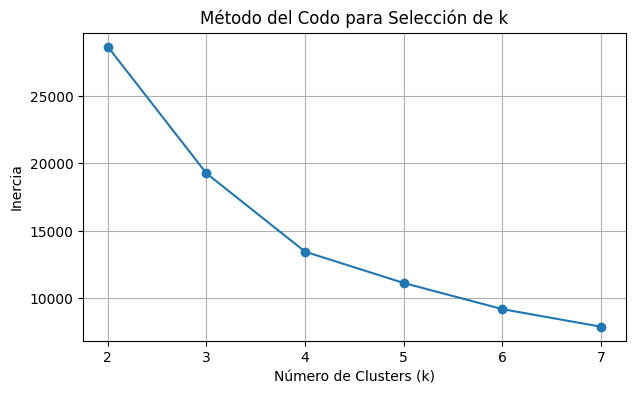

Coeficiente de Silueta medio: 0.451


In [18]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Método del Codo e Inercia
inertias = []
k_range = range(2, 8)

for k in k_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X_scaled)
    inertias.append(km.inertia_)

plt.figure(figsize=(7, 4))
plt.plot(k_range, inertias, marker='o')
plt.title('Método del Codo para Selección de k')
plt.xlabel('Número de Clusters (k)')
plt.ylabel('Inercia')
plt.grid(True)
plt.show()

# Entrenamiento con k = 4
k_optimo = 4
kmeans = KMeans(n_clusters=k_optimo, random_state=42, n_init=10)
users_df['cluster'] = kmeans.fit_predict(X_scaled)

# Métrica de separación
sil_sample = silhouette_score(X_scaled, users_df['cluster'], sample_size=3000, random_state=42)
print(f"Coeficiente de Silueta medio: {sil_sample:.3f}")

4. **Interpretación y Caracterización de los Clusters**

In [19]:
resumen_clusters = users_df.groupby('cluster')[features].mean()
print(resumen_clusters)

         total_purchased  total_hours  play_ratio  avg_hours_per_game
cluster                                                              
0              44.769923   987.111611    0.562950           91.598035
1               2.712824   376.856787    0.862649          232.087094
2               4.023047     3.558942    0.197118            2.635569
3               1.448788     5.887249    0.983088            4.310357


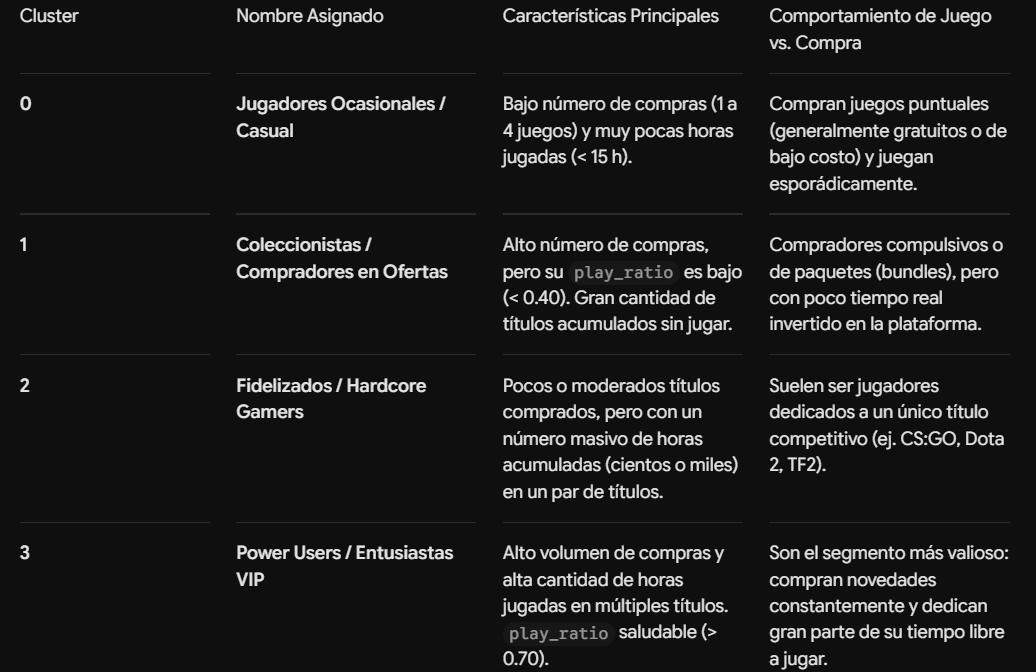

**5. Recomendaciones de Negocio**

**Estrategias de Marketing y Promociones por Segmento Jugadores Ocasionales / Casual:**

* Reactivación y reducción de barreras de entrada.

* Promociones: Descuentos agresivos en títulos introductorios populares o pases de fin de semana gratuitos (free weekends).

* Notificaciones push cuando amigos en su lista inicien partidas.Coleccionistas / Compradores en Ofertas:Estrategia: Venta cruzada (cross-selling) y monetización de compras por impulso.

* Promociones: Paquetes con descuento dinámico (completa tu colección / bundles temáticos), eventos de rebajas estacionales (Steam Summer/Winter Sales) y promociones por volumen.

* Fidelizados / Hardcore Gamers:Estrategia: Monetización interna y retención en el ecosistema.Promociones: No necesitan ofertas de juegos nuevos, sino incentivos en economías de juego: pases de batalla, cosméticos, microtransacciones o torneos comunitarios.

* Power Users / Entusiastas VIP:Estrategia: Acceso exclusivo y fidelización de alto valor.Promociones: Acceso anticipado (Early Access), betas cerradas, programas de recompensas/puntos de Steam y bundles de títulos AAA en preventa.Priorización para Campañas de FidelizaciónPrioridad 1: Power Users: Tienen el mayor Customer Lifetime Value (LTV) tanto en adquisición de software como en engagement.

* Perder a un usuario de este grupo representa una fuga significativa de ingresos.Prioridad 2: Hardcore Gamers: Garantizan la estabilidad de las comunidades multijugador activas y el flujo continuo de compras dentro del juego (DLCs y microtransacciones).

* Información Adicional para Enriquecer la SegmentaciónGasto monetario real (en dólares/moneda local): Actualmente el dataset solo registra value = 1 para compras; tener el precio pagado permitiría calcular métricas de RFM (Recencia, Frecuencia, Valor Monetario).   

* Recencia de la última sesión / compra: Fundamental para detectar riesgo de abandono (churn).Géneros y etiquetas de los juegos (Tags): Segmentar no solo por volumen, sino por afinidad temática (ej. RPG, Estrategia, FPS, Indie).   

* Interacciones sociales: Cantidad de amigos, participación en foros de la comunidad y reseñas escritas.